# Advective contribution to atmospheric energy budget
The atmospheric energy budget has a term related to advection, which I have previously obtained as a residual. Here, I compare this to a direct approach to calculating the advection component. The direct component has the advantage that the advection can be split up between zonal, meridional, and vertical advection.

In [71]:
import sys
import os
import inspect
from matplotlib.lines import Line2D


from isca_tools.thesis.adiabat_theory import get_temp_adiabat
from isca_tools.thesis.season_annual_harmonic import get_phase_amp
from isca_tools.thesis.surface_flux_taylor_2layer import get_sensitivity_lh
from isca_tools.utils.moist_physics import sphum_sat
from isca_tools.utils.numerical import sum_complex
from isca_tools.thesis.lapse_integral_simple import get_lnb_ind, get_temp_2_layer_approx
from isca_tools.utils.xarray import wrap_with_apply_ufunc, isel_float
from isca_tools.utils.numerical import spline_deriv_nonperiodic
from isca_tools.utils.land import get_land_coords, get_ocean_coords
from isca_tools.utils import area_weighting

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth, lapse_dry
from tqdm.notebook import tqdm
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from isca_tools.plot import fig_resize, update_fontsize, update_linewidth, savefig, label_subplots
import isca_tools
from isca_tools.utils.load import load_namelist
from isca_tools.utils.base import mass_weighted_vertical_integral
# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

In [149]:
from jobs.thesis_season.publish_figs.load import smooth_n_days, get_annual_zonal_mean, spline_deriv_periodic_xr, frierson_atmospheric_heating, day_seconds, width
from jobs.thesis_season.publish_figs.xr_funcs import get_fourier_fit_xr, fourier_series_xr
# var_keep = ['ps', 't_surf', 'temp', 'height', 'sphum', 'ucomp', 'vcomp', 'omega', 'swdn_toa', 'swdn_sfc', 'lwup_sfc', 'lwdn_sfc', 'olr', 'flux_t', 'flux_lhe']

exp_dir = 'nerc_srm/simulations/column/'
exp_name = ['base', 'play/k=1_5_sw_reduced', 'play/k=1_5', 'play/sw_reduced']
n_exp = len(exp_name)
n_days_year = 360
# namelist = load_namelist(exp_path)
ds = []
ds_smooth = []
for i in tqdm(range(n_exp)):
    exp_path = os.path.join(exp_dir, exp_name[i])
    namelist = load_namelist(exp_path)
    ds.append(isca_tools.load_dataset(exp_path, first_month_file=2).sel(lat=slice(0, 90)).load())
    ds[i].attrs['omega'] = 2 * np.pi / (day_seconds * n_days_year)
    ds_smooth.append(get_annual_zonal_mean(ds[i], smooth_n_days=smooth_n_days))

  0%|          | 0/4 [00:00<?, ?it/s]

### Annual mean temperature
Below I show that the area weighed mean temperature is similar for the SRM and PI proxy simulations. And there is residual surface polar amplification in the annual mean temperature for the SRM versus PI simulations.

Experiment base: 285.17
Experiment k=1_5_sw_reduced: 285.83
Experiment k=1_5: 290.25
Experiment sw_reduced: 280.42


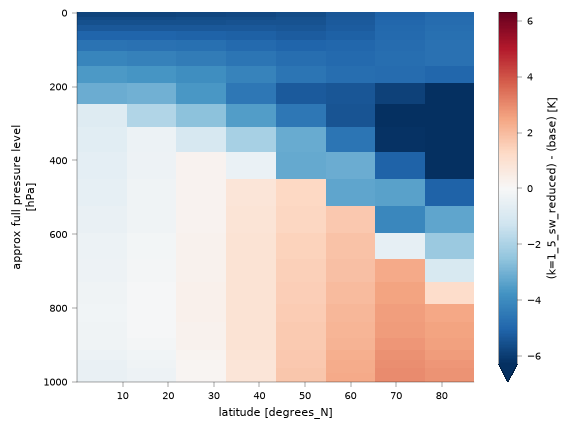

In [150]:
for i in range(n_exp):
    print(f"Experiment {exp_name[i].replace('play/', '')}: {area_weighting(ds[i].t_surf).mean():.2f}")

ax = (ds_smooth[1].temp - ds_smooth[0].temp).mean(dim='time').plot(robust=True)
ax.axes.invert_yaxis()
ax.colorbar.set_label(f'({exp_name[1].replace("play/", "")}) - ({exp_name[0]}) [K]')
plt.show()

## Fourier Decomposition
Here I plot info relating to the annual and 2nd harmonic of both insolation and surface temperature. The idea being that the variation between simulations is dominated by the annual harmonic, with the modification due to the second harmonic remaining pretty constant between them.

In [151]:
for i in range(n_exp):
    _, ds_smooth[i]['sw_coef_amp'], ds_smooth[i]['sw_coef_phase'] = get_fourier_fit_xr(ds_smooth[i].time, ds_smooth[i].swdn_toa, n_harmonics=2, pad_coefs_phase=True)
    _, ds_smooth[i]['t_surf_coef_amp'], ds_smooth[i]['t_surf_coef_phase'] = get_fourier_fit_xr(ds_smooth[i].time, ds_smooth[i].t_surf, n_harmonics=2, pad_coefs_phase=True)

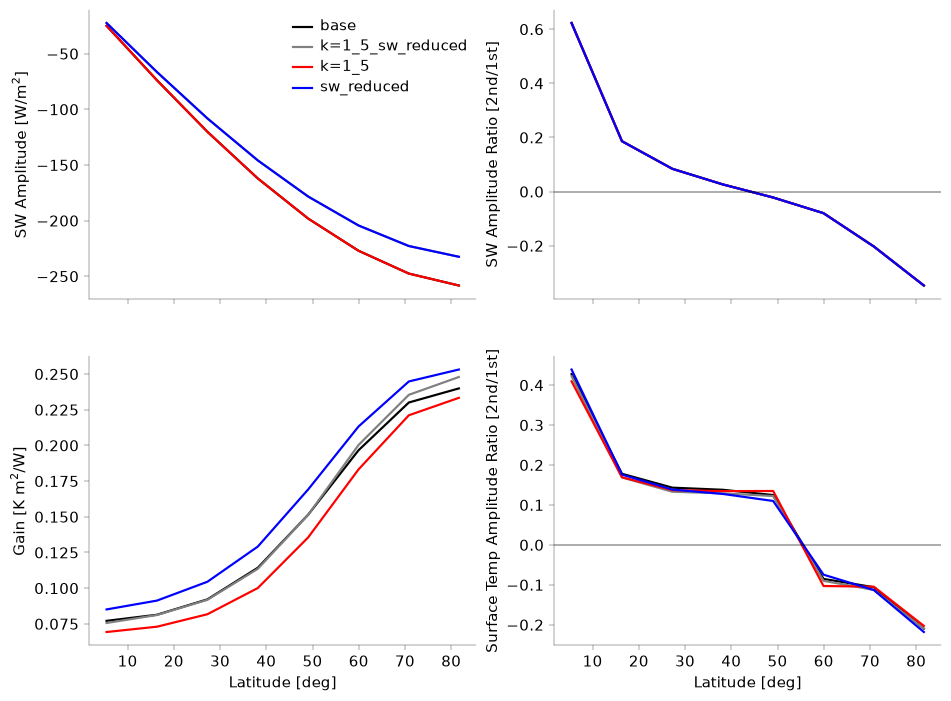

In [152]:
color_exp = {'base': 'black', 'play/k=1_5_sw_reduced': 'gray', 'play/k=1_5': 'red', 'play/sw_reduced': 'blue'}
fig, ax = plt.subplots(2, 2, sharex=True)
fig_resize(fig, width['two_col']*2)
for i in range(n_exp):
    ax[0, 0].plot(ds_smooth[i].lat, ds_smooth[i]['sw_coef_amp'].sel(harmonic=1), label=exp_name[i].replace('play/', ''), color=color_exp[exp_name[i]])
    ax[0, 1].plot(ds_smooth[i].lat, (ds_smooth[i]['sw_coef_amp'].sel(harmonic=2)/ds_smooth[i]['sw_coef_amp'].sel(harmonic=1)), color=color_exp[exp_name[i]])
    ax[1, 0].plot(ds_smooth[i].lat, ds_smooth[i]['t_surf_coef_amp'].sel(harmonic=1)/ds_smooth[i]['sw_coef_amp'].sel(harmonic=1), color=color_exp[exp_name[i]])
    ax[1, 1].plot(ds_smooth[i].lat, (ds_smooth[i]['t_surf_coef_amp'].sel(harmonic=2)/ds_smooth[i]['t_surf_coef_amp'].sel(harmonic=1)), color=color_exp[exp_name[i]])
update_linewidth(fig)
ax[0, 0].set_ylabel('SW Amplitude [W/m$^2$]')
ax[0, 1].set_ylabel('SW Amplitude Ratio [2nd/1st]')
ax[1, 0].set_ylabel('Gain [K m$^2$/W]')
ax[1, 1].set_ylabel('Surface Temp Amplitude Ratio [2nd/1st]')
ax[0, 0].legend()
for i in range(2):
    ax[0, 1].axhline(0, color='black', lw=ax_linewidth)
    ax[1, 1].axhline(0, color='black', lw=ax_linewidth)
    ax[1, i].set_xlabel('Latitude [deg]')
update_fontsize(fig, 7)
plt.show()

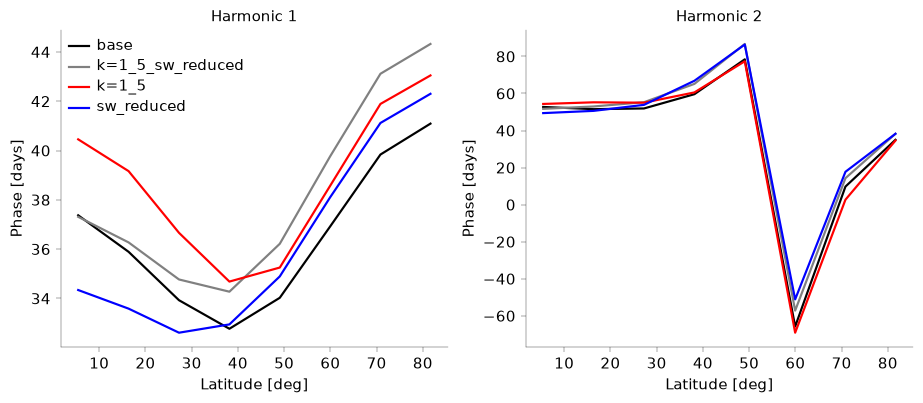

In [160]:
fig, ax = plt.subplots(1, 2, sharex=True)
fig_resize(fig, width['two_col']*2)
for i in range(n_exp):
    ax[0].plot(ds_smooth[i].lat, ds_smooth[i]['t_surf_coef_phase'].sel(harmonic=1)/day_seconds/ds[0].attrs['omega'], color=color_exp[exp_name[i]], label=exp_name[i].replace('play/', ''))
    ax[1].plot(ds_smooth[i].lat, ds_smooth[i]['t_surf_coef_phase'].sel(harmonic=2)/day_seconds/ds[0].attrs['omega'], color=color_exp[exp_name[i]])
update_linewidth(fig)
ax[0].set_ylabel('Phase [days]')
ax[1].set_ylabel('Phase [days]')
ax[0].legend()
for i in range(2):
    ax[i].set_title(f'Harmonic {i+1}')
    ax[i].set_xlabel('Latitude [deg]')
update_fontsize(fig, 7)
plt.show()

### Extrema
Here, I plot the time and temperature of the extrema. I also give option to normalise by the annual harmonic, the idea here is that the deviation from the annual harmonic remains pretty constant for the SRM and PI type simulations.

In [ ]:
from jobs.thesis_season.thesis_figs.utils import get_temp_extrema_numerical_xr
# Record phase of maxima / minima relative to extrema times of 1st harmonic of SW radiation
time_extrema_sw = {'min': int(ds_smooth[0].time[0]), 'max': int(ds_smooth[0].time[int(ds_smooth[0].time.size / 2)])}

# Initialize ds_extrema
extrema_info = {key: [] for key in ['time_min', 'time_max', 'amp_min', 'amp_max']}

for i in range(n_exp):
    var = get_temp_extrema_numerical_xr(ds_smooth[i].time, ds_smooth[i].t_surf-ds_smooth[i].t_surf.mean(dim='time'))
    for j in range(len(var)):
        extrema_info[list(extrema_info.keys())[j]].append(var[j])

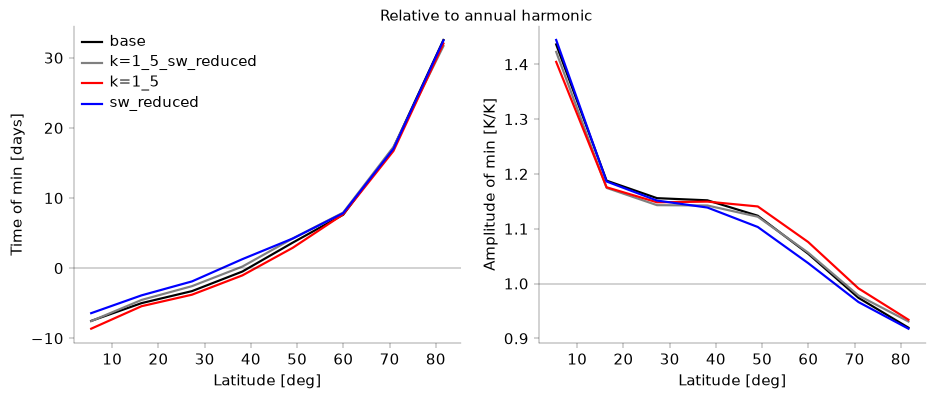

In [228]:
extrema_plot = 'min'
norm_by_annual_harmonic = True
fig, ax = plt.subplots(1, 2)
fig_resize(fig, width['two_col']*2)
for i in range(n_exp):
    var = extrema_info[f'time_{extrema_plot}'][i]
    var_amp = extrema_info[f'amp_{extrema_plot}'][i]
    if norm_by_annual_harmonic:
        var = var - time_extrema_sw[extrema_plot] - ds_smooth[i]['t_surf_coef_phase'].sel(harmonic=1)/day_seconds/ds[0].attrs['omega']
        var_amp = var_amp/np.abs(ds_smooth[i]['t_surf_coef_amp'].sel(harmonic=1))
    else:
        var_amp = var_amp/np.abs(ds_smooth[i]['sw_coef_amp'].sel(harmonic=1))
    ax[0].plot(ds_smooth[i].lat, var, color=color_exp[exp_name[i]], label=exp_name[i].replace('play/', ''))
    ax[1].plot(ds_smooth[i].lat, var_amp, color=color_exp[exp_name[i]], label=exp_name[i].replace('play/', ''))
update_linewidth(fig)
ax[0].legend()
ax[0].set_ylabel(f'Time of {extrema_plot} [days]')
ax[1].set_ylabel(f'Gain of {extrema_plot} [K / W m$^{-2}$]')
for i in range(2):
    ax[i].set_xlabel('Latitude [deg]')
    if norm_by_annual_harmonic:
        ax[i].axhline(i, color='k', lw=ax_linewidth)
if norm_by_annual_harmonic:
    ax[1].set_ylabel(f'Amplitude of {extrema_plot} [K/K]')
    fig.suptitle('Relative to annual harmonic', y=0.92)
update_fontsize(fig, 7)
plt.show()